# Explorando los datos del Observatorio Canguro

Notas para el grupo, para que todos tengamos el mismo mapa de los datos antes de meternos con el modelo. La idea es ver qué hay en la base, qué tan confiable es y qué cosas raras aparecen en cada una de las tres capas que queremos vigilar:

| Capa | Lo que nos preguntamos | Ejemplo |
|---|---|---|
| **Medición** | ¿Este valor tiene sentido? | un peso de 233 kg, un hematocrito de -1, una fecha en el año 5020 |
| **Paciente** | ¿Este niño crece como se espera? | una talla que baja entre visitas |
| **Sede** | ¿Esta sede está midiendo distinto? | una báscula que empieza a sumar 150 g |

Cada sección arranca con la pregunta, después vienen las tablas o gráficos y al final un "Qué vemos" con las cifras de esta misma ejecución. Al final están los retos que esto nos deja, cómo vamos a armar el modelo con todo eso y lo que hay que preguntarle a la Fundación. En el plan del modelo estas tres capas se vuelven cinco (sección 10).

Todo lo que se muestra es agregado: no hay identificadores ni filas de pacientes, y la base se consulta en modo de solo lectura.

**Ojo, la base cambió.** Estos resultados se calcularon entre el 12 y el 14 de octubre de 2026. El 15 de octubre la Fundación restringió la fecha exacta de nacimiento, la sede, la llave del paciente y las fechas de hospitalización (`consumo.variable_restringida`); después volvió a habilitar todo salvo la llave. Las secciones que usan sede o fecha de nacimiento no se han vuelto a correr: el modelo de `modelo_anomalias.ipynb` trabaja sin esas variables, y volver a usarlas es una de las decisiones abiertas del proyecto.

## Cómo está armado

Nuestro sistema tiene que ser **general**: los expertos pueden agregar variables cuando quieran, y la idea es que sirva para otras fuentes, no solo para la Fundación Canguro. Por eso el código está separado en tres piezas:

| Pieza | Archivo | Qué hace | ¿Hay que tocarlo si llega una variable nueva? |
|---|---|---|---|
| **Motor** | `anomalias/motor.py` | Chequeos genéricos que se guían por el diccionario: tipo, unidad, rango, centinelas, dígitos redondeados, fechas, trayectorias, comparación con pares y deriva por sede | No |
| **Adaptador** | `sevarti/kmc.py` | Cómo leer esta base en particular y qué papel cumple cada columna: paciente, sede, fecha de parto, covariables y medidas repetidas | Solo si la variable continúa una medida repetida (por ejemplo, "peso a los 18 meses") |
| **Notebook** | este archivo | Los textos y los gráficos | No: recorre lo que diga el diccionario |

O sea, si mañana aparece una variable nueva en `consumo.diccionario`, sale sola en el perfil de variables, en la revisión del diccionario, en la completitud y en los chequeos de medición. Al final de la sección 2 se compara el diccionario con el de la ejecución anterior, para ver qué se agregó, qué se quitó y qué cambió.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, str(Path('..').resolve()))  # carpeta del proyecto: de ahí se importan los paquetes

from sevarti import kmc as K
import graficos as G
from anomalias import motor as M

warnings.filterwarnings('ignore', category=RuntimeWarning)
G.use_style()


def md(text: str) -> None:
    display(Markdown(text))


def dec(x: float, digits: int = 1) -> str:
    # Spanish number format: '.' for thousands, ',' for decimals.
    return f'{x:,.{digits}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def sdec(x: float, digits: int = 2) -> str:
    return ('+' if x >= 0 else '') + dec(x, digits)


def fmt(n: float) -> str:
    return dec(n, 0)


def pct(x: float, digits: int = 1) -> str:
    return dec(x, digits) + '%'


pd.set_option('display.max_rows', 80, 'display.max_columns', 40, 'display.width', 200,
              'display.float_format', lambda v: fmt(v) if float(v).is_integer() else dec(v, 2))

## 0. Conexión y carga

Usamos el usuario `kmc_estudiante`, que es de solo lectura. La clave **no** está en el notebook: se lee de la variable de entorno `KMC_PW`. Traemos cuatro cosas:

- el diccionario;
- la tabla ancha `consumo.perfil_paciente`, con una fila por paciente;
- dos resúmenes de la tabla larga `consumo.medicion`, que se calculan en el servidor para no bajar filas individuales.

In [2]:
t0 = time.time()
with K.connect() as conn:
    meta = K.load_metadata(conn)
    raw = K.load_wide(conn)
    flags = K.load_flags(conn)
    ubicacion = K.load_stage_locations(conn)

identificador_expuesto = [c for c in K.IDENTIFIERS if c in raw.columns and c != 'paciente_id']
wide = raw.drop(columns=identificador_expuesto)  # never analysed, never shown
data = K.prepare(wide)
spec = K.build_spec(wide)
fechas = {c: M.parse_dates(data[c]) for c in meta.loc[meta.kind == 'date', 'variable'] if c in data}
parto = fechas[spec.anchor_date].date

md(f'Cargado en {time.time() - t0:.0f} s: **{fmt(len(wide))} pacientes**, '
   f'**{fmt(len(meta))} variables** en el diccionario y **{fmt(flags.n.sum())} mediciones** en la tabla larga. '
   f'La base no dice cuándo se extrajo, así que tomamos como fecha de corte la última visita plausible: '
   f'**{spec.cutoff:%d/%m/%Y}**.')

Cargado en 66 s: **62.043 pacientes**, **339 variables** en el diccionario y **13.884.056 mediciones** en la tabla larga. La base no dice cuándo se extrajo, así que tomamos como fecha de corte la última visita plausible: **24/07/2026**.

## 1. ¿Cuántos pacientes hay?

Queremos saber cuántos pacientes hay de verdad, cómo se reparten por sede y por año, y si hay años en los que falta información.

In [3]:
documentado = pd.DataFrame({
    'documentación': [K.DOCUMENTED['pacientes'], K.DOCUMENTED['variables'], K.DOCUMENTED['mediciones']],
    'base consultada': [len(wide), len(meta) + len(identificador_expuesto), int(flags.n.sum())],
}, index=['pacientes', 'variables', 'mediciones (tabla larga)'])
documentado['razón'] = documentado['base consultada'] / documentado['documentación']
documentado.style.format({'documentación': fmt, 'base consultada': fmt, 'razón': lambda v: dec(v, 1) + 'x'})

,documentación,base consultada,razón
pacientes,15.641,62.043,"4,0x"
variables,337,340,"1,0x"
mediciones (tabla larga),4.521.712,13.884.056,"3,1x"


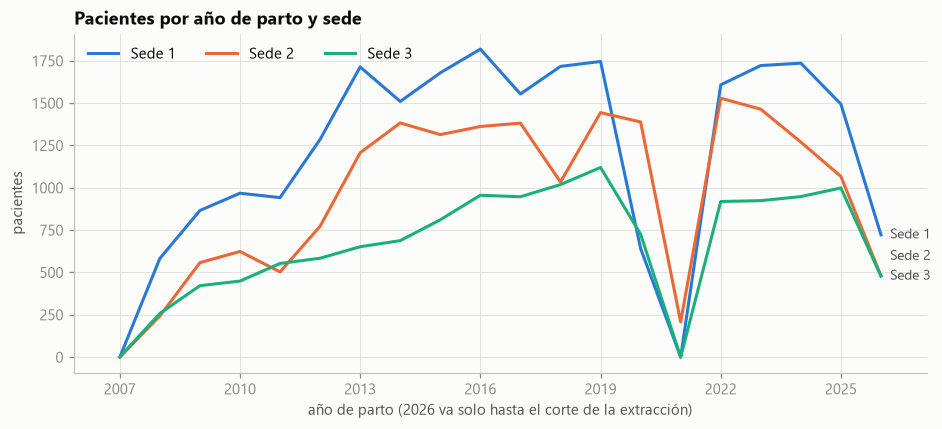

anio_parto,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
sede 1,0,583,866,968,942,1286,1714,1510,1679,1819,1554,1717,1746,642,0,1608,1722,1736,1494,722
sede 2,0,243,558,624,503,773,1207,1383,1314,1362,1382,1034,1444,1389,208,1529,1464,1270,1067,480
sede 3,1,258,422,449,553,584,652,688,811,956,947,1019,1120,726,0,919,924,948,999,478
total,1,1084,1846,2041,1998,2643,3573,3581,3804,4137,3883,3770,4310,2757,208,4056,4110,3954,3560,1680


In [4]:
# Counts: a year without patients is a real zero, not a gap.
cohorte = (data.groupby(['anio_parto', 'iden_sede']).size().unstack(fill_value=0)
           .stack().rename('pacientes').reset_index())
ax = G.lines_by_group(cohorte, 'anio_parto', 'pacientes', 'iden_sede',
                      'Pacientes por año de parto y sede', 'pacientes')
ax.set_xlabel(f'año de parto ({spec.cutoff.year} va solo hasta el corte de la extracción)')
plt.show()

tabla_cohorte = cohorte.pivot(index='anio_parto', columns='iden_sede', values='pacientes').fillna(0).astype(int)
tabla_cohorte.columns = [f'sede {int(c)}' for c in tabla_cohorte.columns]
tabla_cohorte['total'] = tabla_cohorte.sum(axis=1)
tabla_cohorte.index = tabla_cohorte.index.astype(int)
display(tabla_cohorte.T)

In [5]:
# Abrupt drops: a year below 40% of the median of its neighbouring years, per site.
anios = tabla_cohorte.drop(columns='total')
vecinos = anios.rolling(5, center=True, min_periods=3).median()
caidas = (anios < 0.4 * vecinos) & (vecinos >= 100)
caidas = caidas.loc[(caidas.index > anios.index.min()) & (caidas.index < anios.index.max())]
lista_caidas = [f'{c} en {a}' for a, fila in caidas.iterrows() for c, v in fila.items() if v]
sin_parto = data[spec.anchor_date].isna().groupby(data.iden_sede).mean() * 100

md(f'''**Qué vemos**
- Hay **{dec(documentado.loc["pacientes", "razón"])} veces** más pacientes y **{dec(documentado.loc["mediciones (tabla larga)", "razón"])} veces** más mediciones que lo que dice la documentación. La documentación está vieja, así que cuando citemos cifras toca decir siempre de qué fecha de extracción son.
- Hay años en los que el registro se cae de golpe: {", ".join(lista_caidas) or "ninguno"}. En 2021 solo registra la sede 2 ({fmt(tabla_cohorte.loc[2021, "sede 2"])} pacientes); las sedes 1 y 3 no tienen ninguno.
- A la sede {int(sin_parto.idxmax())} le falta la fecha de parto en el **{pct(sin_parto.max())}** de los pacientes, mientras que en las otras sedes casi nunca falta ({pct(sin_parto.drop(sin_parto.idxmax()).max())} como máximo). Sin fecha de parto no podemos ubicar sus controles en el tiempo.''')

**Qué vemos**
- Hay **4,0 veces** más pacientes y **3,1 veces** más mediciones que lo que dice la documentación. La documentación está vieja, así que cuando citemos cifras toca decir siempre de qué fecha de extracción son.
- Hay años en los que el registro se cae de golpe: sede 1 en 2020, sede 1 en 2021, sede 2 en 2021, sede 3 en 2021. En 2021 solo registra la sede 2 (208 pacientes); las sedes 1 y 3 no tienen ninguno.
- A la sede 1 le falta la fecha de parto en el **17,2%** de los pacientes, mientras que en las otras sedes casi nunca falta (0,0% como máximo). Sin fecha de parto no podemos ubicar sus controles en el tiempo.

## 2. ¿Podemos confiar en el diccionario?

El motor usa el diccionario para validar cada valor. Si un rango, una unidad o un tipo están mal puestos, el detector se equivoca sin que nos demos cuenta. Así que vale la pena revisarlo antes que nada.

In [6]:
resumen_tipos = meta.groupby(['module', 'kind']).size().unstack(fill_value=0)
resumen_tipos['total'] = resumen_tipos.sum(axis=1)
display(resumen_tipos.sort_values('total', ascending=False))

auditoria = M.audit_metadata(meta, wide, spec.entity)
display(auditoria.chequeo.value_counts().rename('variables afectadas').to_frame())
display(auditoria[auditoria.chequeo != 'Numérica sin unidad'].reset_index(drop=True))

kind,boolean,categorical,date,numeric,text,total
module,,,,,,
seguimiento (v###),0,96,9,57,8,170
cp,20,8,0,23,0,51
hd,3,7,3,33,0,46
pa,8,10,0,5,0,23
ac,8,6,0,2,0,16
csp,2,8,0,5,0,15
ern,1,6,1,5,0,13
iden,1,0,1,1,0,3
ec,0,0,0,2,0,2


,variables afectadas
chequeo,
Numérica sin unidad,37
Rango igual al mínimo y máximo observados,11
Etiqueta duplicada,4
Numérica sin rango declarado,3
Rango excluye el valor más frecuente,2
En el diccionario pero no en los datos,1


,variable,chequeo,detalle
0,csp_ingreso_smmlv,En el diccionario pero no en los datos,la variable no se puede analizar
1,"v323, v408",Etiqueta duplicada,"""6mEC Normal"" describe variables distintas"
2,"v304, v317g",Etiqueta duplicada,"""6mEC Peso"" describe variables distintas"
3,"v347, v360g",Etiqueta duplicada,"""9mEC Peso"" describe variables distintas"
4,"v232, v271",Etiqueta duplicada,"""Fecha de abandono de la posición canguro"" des..."
5,csp_ingreso_smmlv,Numérica sin rango declarado,no se puede validar el valor contra el diccion...
6,ec_3m,Numérica sin rango declarado,no se puede validar el valor contra el diccion...
7,ec_9m,Numérica sin rango declarado,no se puede validar el valor contra el diccion...
8,cp_hormonales,Rango excluye el valor más frecuente,"0 (84% de los registros) queda fuera de [1, 13]"
9,cp_medgeneral,Rango igual al mínimo y máximo observados,"[0, 50]: el rango parece calculado de los dato..."


In [7]:
# Cross-variable unit check: v196d says weeks, but does it behave like days since birth?
dias_entrada = (fechas['v195a'].date - parto).dt.days
v196d = data.v196d
comparables = v196d.notna() & dias_entrada.between(0, 400)
coincide_dias = ((v196d - dias_entrada).abs() <= 1)[comparables].mean() * 100
coincide_semanas = ((v196d - dias_entrada / 7).abs() <= 1)[comparables].mean() * 100

md(f'''**Qué vemos**
- **{auditoria.chequeo.eq("Rango igual al mínimo y máximo observados").sum()} variables tienen como rango justo el mínimo y el máximo de los datos.** O sea, el rango salió de los propios datos y no de un criterio clínico. Por ejemplo, la edad gestacional por ecografía (`ern_eco`) acepta de -0,3 a 134,6 semanas. Con rangos así, la bandera `en_rango` de la base nunca falla, así que no nos sirve como detector.
- **En {auditoria.chequeo.eq("Rango excluye el valor más frecuente").sum()} variables el rango deja por fuera el valor más común.** En `hd_ultivalorhematocrito` es el código -1, que aparece en el 68% de los registros; en `cp_hormonales` es el 0, que quiere decir "ninguno".
- **Hay nombres repetidos.** Por ejemplo, `v304` y `v317g` se llaman las dos "6mEC Peso". Y `v408` se llama "6mEC Normal" pero está en el bloque de 12 meses.
- **Hay una unidad mal puesta.** `v196d` dice estar en semanas, pero cuadra con los días entre el parto y la entrada al programa en el **{pct(coincide_dias)}** de los casos, y con semanas solo en el {pct(coincide_semanas)}.
- **{auditoria.chequeo.eq("Numérica sin unidad").sum()} variables numéricas no tienen unidad.** En esas no podemos decir si un valor es un error de unidad.''')

**Qué vemos**
- **11 variables tienen como rango justo el mínimo y el máximo de los datos.** O sea, el rango salió de los propios datos y no de un criterio clínico. Por ejemplo, la edad gestacional por ecografía (`ern_eco`) acepta de -0,3 a 134,6 semanas. Con rangos así, la bandera `en_rango` de la base nunca falla, así que no nos sirve como detector.
- **En 2 variables el rango deja por fuera el valor más común.** En `hd_ultivalorhematocrito` es el código -1, que aparece en el 68% de los registros; en `cp_hormonales` es el 0, que quiere decir "ninguno".
- **Hay nombres repetidos.** Por ejemplo, `v304` y `v317g` se llaman las dos "6mEC Peso". Y `v408` se llama "6mEC Normal" pero está en el bloque de 12 meses.
- **Hay una unidad mal puesta.** `v196d` dice estar en semanas, pero cuadra con los días entre el parto y la entrada al programa en el **94,2%** de los casos, y con semanas solo en el 0,5%.
- **37 variables numéricas no tienen unidad.** En esas no podemos decir si un valor es un error de unidad.

In [8]:
snapshot_path = Path('diccionario_snapshot.csv')
anterior = pd.read_csv(snapshot_path) if snapshot_path.exists() else None
cambios = M.diff_metadata(meta, anterior)
meta[list(M.METADATA_COLUMNS)].to_csv(snapshot_path, index=False)  # metadata only, no patient data

if anterior is None:
    md('**¿Hay variables nuevas?** Es la primera ejecución, así que guardamos el diccionario en '
       '`diccionario_snapshot.csv`. La próxima vez se compara contra ese archivo y se listan las variables nuevas, eliminadas o cambiadas.')
elif cambios.empty:
    md('**¿Hay variables nuevas?** No: el diccionario está igual que en la ejecución anterior.')
else:
    md(f'**¿Hay variables nuevas?** Desde la última ejecución hay {len(cambios)} cambios en el diccionario. Las variables nuevas '
       'ya están incluidas en todas las secciones.')
    display(cambios)

**¿Hay variables nuevas?** No: el diccionario está igual que en la ejecución anterior.

## 3. ¿Cuánta información hay?

Aquí hay que separar dos cosas: lo que falta porque el niño todavía no tiene edad para esa visita, y lo que falta porque de verdad se perdió el seguimiento.

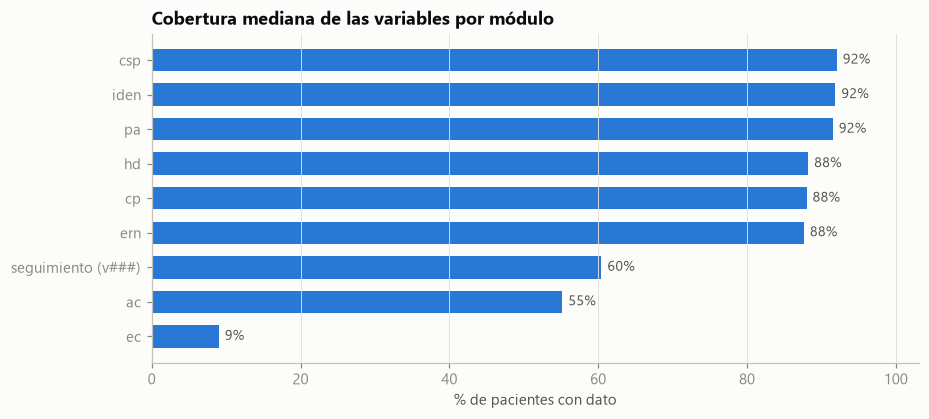

**16 variables tienen datos en menos del 10% de los pacientes**, así que no nos van a servir mucho para modelar. Las más vacías: 9mEC Rotavirus, 12mEC Peso (Cuándo?), 12mEC dias cuándo?), 9mEC Peso, 9mEC dias, 6mEC Peso.

In [9]:
perfil = M.profile_variables(meta, data, spec)
perfil = perfil.join(meta.set_index('variable')[['module']])
cobertura_modulo = perfil.groupby('module').pct_cobertura.median().rename('cobertura mediana (%)')
G.barh(cobertura_modulo, 'Cobertura mediana de las variables por módulo', '% de pacientes con dato', fmt=lambda v: pct(v, 0))
plt.show()
pocas = perfil[perfil.pct_cobertura < 10]
md(f'**{len(pocas)} variables tienen datos en menos del 10% de los pacientes**, así que no nos van a servir mucho para modelar. '
   f'Las más vacías: {", ".join(pocas.sort_values("pct_cobertura").etiqueta.head(6))}.')

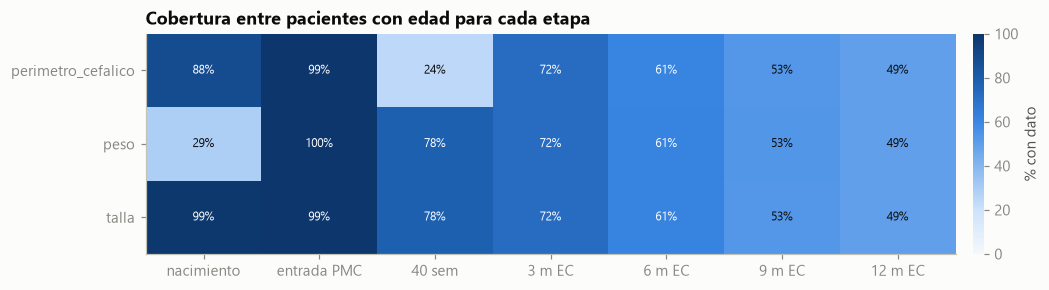

,elegibles,con_dato_elegibles,pct_cobertura_elegibles
etapa,,,
nacimiento,55560,15920,"28,65"
entrada PMC,56996,56747,"99,56"
40 sem,55560,43343,"78,01"
3 m EC,54792,39511,"72,11"
6 m EC,53888,33050,"61,33"
9 m EC,52921,28143,"53,18"
12 m EC,51998,25671,"49,37"


In [10]:
coberturas = []
for fam in spec.families:
    largo = M.long_family(data, fam, spec)
    c = M.eligible_coverage(largo, spec).assign(familia=fam.concept)
    coberturas.append(c)
coberturas = pd.concat(coberturas)
tabla = coberturas.pivot(index='familia', columns='etapa', values='pct_cobertura_elegibles')
tabla = tabla[[s.key for s in spec.families[0].stages]]
G.heatmap(tabla, 'Cobertura entre pacientes con edad para cada etapa', '% con dato', fmt=lambda v: pct(v, 0),
          vmin=0, vmax=100, figsize=(10, 2.6))
plt.show()
peso_cob = coberturas[coberturas.familia == 'peso'].set_index('etapa')
display(peso_cob[['elegibles', 'con_dato_elegibles', 'pct_cobertura_elegibles']])

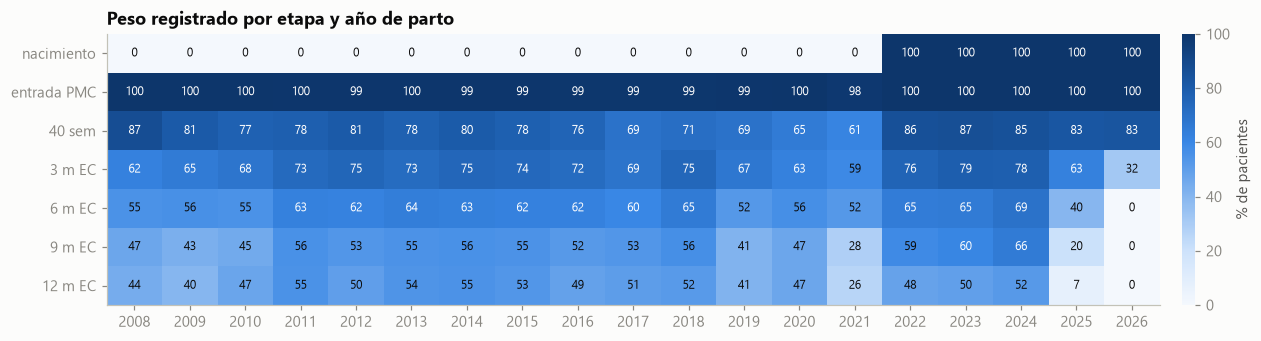

**Qué vemos**
- Si contamos solo a los niños que ya tienen edad para cada visita, el peso pasa de estar en el **78%** a las 40 semanas al **49%** a los 12 meses. Esa es la pérdida de seguimiento real; las cifras brutas la exageran porque meten a niños que todavía no cumplen la edad.
- En el mapa por año es normal que las columnas más recientes estén bajas, porque esos niños no han llegado a la visita. Las de 2020 y 2021 caen por los huecos de registro de la sección 1.

In [11]:
por_anio = (M.long_family(data, spec.family('peso'), spec)
            .assign(anio=lambda d: d.anchor.dt.year)
            .query('anio >= 2008')
            .groupby(['stage', 'anio']).value.apply(lambda s: s.notna().mean() * 100).unstack())
por_anio = por_anio.loc[[s.key for s in spec.family('peso').stages]]
por_anio.columns = por_anio.columns.astype(int)
G.heatmap(por_anio, 'Peso registrado por etapa y año de parto', '% de pacientes', fmt='{:.0f}', vmin=0, vmax=100,
          figsize=(13, 3.2))
plt.show()

c12 = peso_cob.loc['12 m EC', 'pct_cobertura_elegibles']
c40 = peso_cob.loc['40 sem', 'pct_cobertura_elegibles']
md(f'''**Qué vemos**
- Si contamos solo a los niños que ya tienen edad para cada visita, el peso pasa de estar en el **{pct(c40, 0)}** a las 40 semanas al **{pct(c12, 0)}** a los 12 meses. Esa es la pérdida de seguimiento real; las cifras brutas la exageran porque meten a niños que todavía no cumplen la edad.
- En el mapa por año es normal que las columnas más recientes estén bajas, porque esos niños no han llegado a la visita. Las de 2020 y 2021 caen por los huecos de registro de la sección 1.''')

In [12]:
# Variables that only start being recorded partway through the history: near zero before a year, common after it.
anio_parto = parto.dt.year
presencia = (data[[v for v in meta.variable if v in data]].notna()
             .groupby(anio_parto).mean().mul(100))
presencia = presencia.loc[presencia.index >= 2008]

def anio_inicio(col: pd.Series) -> float:
    activos = col[col >= 20].index
    if len(activos) == 0:
        return np.nan
    antes = col[col.index < activos.min()]
    return activos.min() if len(antes) >= 3 and (antes < 2).all() else np.nan

inicios = presencia.apply(anio_inicio).dropna().astype(int).rename('desde')
etiquetas = meta.set_index('variable').label
por_inicio = (inicios.to_frame().assign(etiqueta=etiquetas.reindex(inicios.index))
              .groupby('desde').agg(variables=('etiqueta', 'size'),
                                    ejemplos=('etiqueta', lambda s: ', '.join(s.head(4)))))
display(por_inicio)

primera_etapa = spec.family('peso').stages[0]
inicio_primera = inicios.get(primera_etapa.value)
grupos = ', '.join(f'{fmt(n)} en {a}' for a, n in por_inicio.variables.items())
md(f'''**Qué vemos**
- **{fmt(len(inicios))} variables no existían al principio**: casi no tienen datos antes de cierto año y después sí. Los arranques se concentran en pocos años ({grupos}), así que parecen versiones nuevas del formulario que agregan bloques de preguntas.'''
   + (f'''
- El peso en la etapa "{primera_etapa.key}" es una de ellas: solo se registra desde {inicio_primera}. Por eso su cobertura sale tan baja; no es que se haya perdido, es que antes no se capturaba.''' if inicio_primera else '')
   + '''
- Esto es justo lo que va a pasar cuando los expertos agreguen variables: **un faltante antes de que la variable exista quiere decir "no se preguntaba", no "falta el dato"**. El sistema tiene que saber desde cuándo existe cada variable y calcular su línea base solo desde ahí.''')

,variables,ejemplos
desde,,
2015,39,"Adaptacion al seno, Tecnica administracion por..."
2019,8,numero de parcial de orina en la hosp neonatal...
2022,29,Edad Gestacional con base en ECO 1er.trimestre...


**Qué vemos**
- **76 variables no existían al principio**: casi no tienen datos antes de cierto año y después sí. Los arranques se concentran en pocos años (39 en 2015, 8 en 2019, 29 en 2022), así que parecen versiones nuevas del formulario que agregan bloques de preguntas.
- El peso en la etapa "nacimiento" es una de ellas: solo se registra desde 2022. Por eso su cobertura sale tan baja; no es que se haya perdido, es que antes no se capturaba.
- Esto es justo lo que va a pasar cuando los expertos agreguen variables: **un faltante antes de que la variable exista quiere decir "no se preguntaba", no "falta el dato"**. El sistema tiene que saber desde cuándo existe cada variable y calcular su línea base solo desde ahí.

## 4. ¿Sirven las banderas que ya trae la base?

La tabla larga ya viene con sus propias banderas de calidad (`tipo_ok`, `en_dominio`, `en_rango`, `temporal_no_ubicable`). La pregunta es si podemos partir de ellas o si toca hacer las nuestras.

In [13]:
total = flags[['n', 'tipo_invalido', 'fuera_dominio', 'fuera_rango', 'rango_no_evaluado', 'no_ubicable', 'con_etapa']].sum()
banderas = pd.DataFrame({'mediciones': total, '% del total': 100 * total / total['n']}).drop(index='n')
banderas.index = ['tipo inválido', 'fuera de dominio', 'fuera de rango', 'rango no evaluado',
                  'sin ubicación temporal', 'con etapa asignada']
display(banderas.style.format({'mediciones': fmt, '% del total': pct}))

ubic = ubicacion.groupby('etapa').n.sum().sort_values(ascending=False)
display((100 * ubic / ubic.sum()).rename('% de mediciones').to_frame().style.format(pct))

por_variable = flags.groupby('variable')[['n', 'fuera_rango', 'fuera_dominio', 'tipo_invalido']].sum()
peores = por_variable.assign(pct_fuera=lambda d: 100 * (d.fuera_rango + d.fuera_dominio + d.tipo_invalido) / d.n)
peores = peores.join(meta.set_index('variable')[['label', 'source_type']]).sort_values('pct_fuera', ascending=False)
display(peores.head(10)[['label', 'source_type', 'n', 'fuera_rango', 'fuera_dominio', 'tipo_invalido', 'pct_fuera']])

rotas = peores[(peores.pct_fuera >= 95) & (peores.n >= 100)]
md(f'''**Qué vemos**
- El **{pct(banderas.loc["sin ubicación temporal", "% del total"], 0)}** de las mediciones está marcado como "sin ubicación temporal" y solo el {pct(banderas.loc["con etapa asignada", "% del total"], 0)} tiene etapa. Eso cuadra con la documentación: el eje de edad corregida todavía no está activo. Pero en la sección 6 vamos a ver que con las fechas de cada visita **sí** se pueden ubicar los controles.
- En el **{pct(banderas.loc["rango no evaluado", "% del total"], 0)}** de las mediciones no se evalúa el rango: son categóricas, fechas o variables sin rango. Y ya vimos en la sección 2 que muchos de los rangos que sí hay salieron de los mismos datos.
- **{len(rotas)} variables fallan una bandera en el 95% o más de sus valores** ({", ".join(f"`{v}`" for v in rotas.index)}). Que falle prácticamente todo no es un error de captura, es que **la regla de validación está mal configurada**: campos de texto marcados como "tipo inválido" o dominios que no incluyen las respuestas que de verdad se usan. Ojo: si filtramos por esas banderas, borramos la variable completa.
- En resumen, las banderas de la base sirven para filtrar algunos errores de tipo y dominio, pero **no reemplazan una capa de medición propia**.''')

,mediciones,% del total
tipo inválido,91.258,"0,7%"
fuera de dominio,151.221,"1,1%"
fuera de rango,109.761,"0,8%"
rango no evaluado,7.982.333,"57,5%"
sin ubicación temporal,10.486.729,"75,5%"
con etapa asignada,3.386.148,"24,4%"


,% de mediciones
etapa,
(sin etapa),"75,6%"
embarazo y pre-parto,"16,4%"
entorno,"6,3%"
caracterizacion,"1,7%"


,label,source_type,n,fuera_rango,fuera_dominio,tipo_invalido,pct_fuera
variable,,,,,,,
v386a,9mEC Rotavirus,CATEGORIC,8179,0,8179,0,100
v365,9mEC Otras,TEXT,17356,0,0,17356,100
v322,6mEC Otras,TEXT,17356,0,0,17356,100
v245,OtraEnf40semEG,TEXT,17356,0,0,17356,100
v407,12mEC Otras Enf,TEXT,17356,0,0,17356,100
v343,6mEC Sarampión,CATEGORIC,19741,0,19649,0,"99,53"
v301,3m Sarampión,CATEGORIC,23779,0,23629,0,"99,37"
v386,9mEC Sarampión,CATEGORIC,9639,0,9556,0,"99,14"
cp_hormonales,Numero de embarazo bajo planificacion con horm...,INTEGER,61717,52002,0,0,"84,26"


**Qué vemos**
- El **76%** de las mediciones está marcado como "sin ubicación temporal" y solo el 24% tiene etapa. Eso cuadra con la documentación: el eje de edad corregida todavía no está activo. Pero en la sección 6 vamos a ver que con las fechas de cada visita **sí** se pueden ubicar los controles.
- En el **57%** de las mediciones no se evalúa el rango: son categóricas, fechas o variables sin rango. Y ya vimos en la sección 2 que muchos de los rangos que sí hay salieron de los mismos datos.
- **8 variables fallan una bandera en el 95% o más de sus valores** (`v386a`, `v365`, `v322`, `v245`, `v407`, `v343`, `v301`, `v386`). Que falle prácticamente todo no es un error de captura, es que **la regla de validación está mal configurada**: campos de texto marcados como "tipo inválido" o dominios que no incluyen las respuestas que de verdad se usan. Ojo: si filtramos por esas banderas, borramos la variable completa.
- En resumen, las banderas de la base sirven para filtrar algunos errores de tipo y dominio, pero **no reemplazan una capa de medición propia**.

In [14]:
# Columns whose out-of-domain content is free text, and variables that the wide view drops entirely.
texto = flags.groupby('variable')[['n', 'fuera_dominio', 'texto_libre_fuera_dominio']].sum()
texto = texto[texto.texto_libre_fuera_dominio > 0].join(meta.set_index('variable')[['label', 'source_type']])
texto = texto.assign(pct_texto_libre=lambda d: 100 * d.texto_libre_fuera_dominio / d.n,
                     en_vista_ancha=lambda d: [int(data[v].notna().sum()) if v in data else 0 for v in d.index])
display(texto.sort_values('texto_libre_fuera_dominio', ascending=False)
        [['label', 'source_type', 'n', 'texto_libre_fuera_dominio', 'pct_texto_libre', 'en_vista_ancha']])

perdidas = [v for v in flags.variable.unique() if v in data and data[v].isna().all()]
if len(texto):
    peor = texto.pct_texto_libre.idxmax()
    n_texto = 'una variable categórica' if len(texto) == 1 else f'{fmt(len(texto))} variables categóricas'
    n_perdidas = 'Una variable tiene' if len(perdidas) == 1 else f'{fmt(len(perdidas))} variables tienen'
    md(f'''**Qué vemos**
- En **{n_texto}** los valores fuera de dominio son frases de tres o más palabras, o sea, texto libre. El caso extremo es `{peor}` ("{texto.loc[peor, "label"]}"): el {pct(texto.loc[peor, "pct_texto_libre"], 0)} de sus valores son notas clínicas en vez de la respuesta esperada. Parece una columna corrida o un campo reutilizado; es un error de esquema, no de medición.
- {n_perdidas} datos en la tabla larga pero ninguno en la vista ancha, porque esa vista descarta los valores inválidos sin avisar. Si solo usamos la vista ancha, no nos enteramos del problema.''')

,label,source_type,n,texto_libre_fuera_dominio,pct_texto_libre,en_vista_ancha
variable,,,,,,
v386a,9mEC Rotavirus,CATEGORIC,8179,8179,100,0


**Qué vemos**
- En **una variable categórica** los valores fuera de dominio son frases de tres o más palabras, o sea, texto libre. El caso extremo es `v386a` ("9mEC Rotavirus"): el 100% de sus valores son notas clínicas en vez de la respuesta esperada. Parece una columna corrida o un campo reutilizado; es un error de esquema, no de medición.
- Una variable tiene datos en la tabla larga pero ninguno en la vista ancha, porque esa vista descarta los valores inválidos sin avisar. Si solo usamos la vista ancha, no nos enteramos del problema.

## 5. Capa de medición: valores que no tienen sentido

¿Qué tipos de error aparecen valor por valor? El motor le pasa los mismos chequeos a **todas** las variables, guiándose por el diccionario:

- **Fuera de rango:** el valor se sale del rango declarado.
- **Centinela:** códigos como -1, 99 o 999 que aparecen muchísimo y por fuera del rango.
- **Error de unidad:** un valor fuera de rango, a más de 5 veces la mediana, que vuelve al rango si lo multiplicamos o dividimos por 10, 100 o 1000 (por ejemplo, gramos escritos como kilos).
- **Atípico robusto:** un valor a más de 5 desviaciones robustas (mediana y MAD) del resto. Si la variable es asimétrica, se calcula en escala logarítmica.
- **Dígito preferido:** qué tan seguido el último dígito es 0. Si nadie redondeara, sería más o menos el 10%.
- **Fechas:** formato, años imposibles, fechas centinela (1970-01-01) y eventos antes del parto.

,etiqueta,module,n,n_fuera_rango,n_centinela,centinelas,n_error_unidad,n_atipico_robusto,n_fecha_imposible,n_antes_de_anclaje,pct_hallazgos
variable,,,,,,,,,,,
cp_hormonales,Numero de embarazo bajo planificacion con horm...,cp,61717,52.002,0,NaN,0,0,NaN,NaN,"84,26"
hd_ultivalorhematocrito,ultimo valor hematocrito,hd,54898,0,37.181,-1,0,20,NaN,NaN,"67,73"
hd_valormasaltobilirubina,Pico mas alto bilirubina,hd,10987,4.442,0,NaN,0,0,NaN,NaN,"40,43"
cp_prematuro,Numero de prematuros,cp,34332,10.109,0,NaN,0,0,NaN,NaN,"29,44"
v402f,12mEC dias cuándo?),seguimiento (v###),351,26,0,NaN,20,0,NaN,NaN,"13,11"
v360f,9mEC dias,seguimiento (v###),477,33,5,9,21,0,NaN,NaN,"12,37"
v402g,12mEC Peso (Cuándo?),seguimiento (v###),318,26,0,NaN,1,0,NaN,NaN,"8,49"
v317f,6mEC dias,seguimiento (v###),1027,43,7,9,25,0,NaN,NaN,"7,30"
v317g,6mEC Peso,seguimiento (v###),939,50,0,NaN,0,0,NaN,NaN,"5,32"


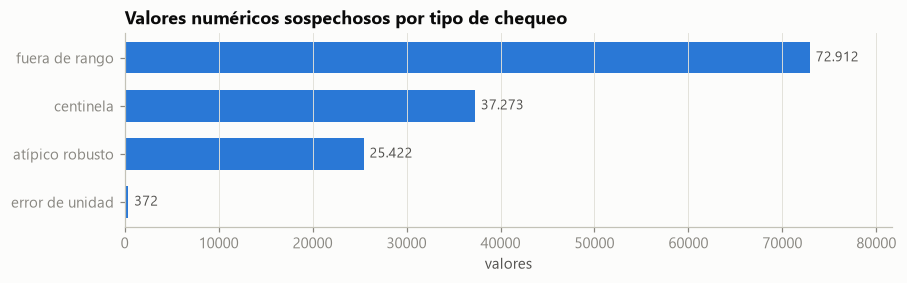

In [15]:
cols = ['etiqueta', 'module', 'n', 'n_fuera_rango', 'n_centinela', 'centinelas', 'n_error_unidad', 'n_atipico_robusto',
        'n_fecha_imposible', 'n_antes_de_anclaje', 'pct_hallazgos']
ranking = perfil[perfil.n >= 100].sort_values('pct_hallazgos', ascending=False)
display(ranking[cols].head(20))

numericas = perfil[perfil.tipo == 'numeric']
conteo = pd.Series({
    'fuera de rango': numericas.n_fuera_rango.sum(), 'centinela': numericas.n_centinela.sum(),
    'error de unidad': numericas.n_error_unidad.sum(), 'atípico robusto': numericas.n_atipico_robusto.sum(),
})
G.barh(conteo, 'Valores numéricos sospechosos por tipo de chequeo', 'valores', fmt=fmt)
plt.show()

In [16]:
centinelas = numericas[numericas.n_centinela > 0][['etiqueta', 'centinelas', 'n_centinela', 'n']]
centinelas['% de los valores'] = 100 * centinelas.n_centinela / centinelas.n
display(centinelas.sort_values('n_centinela', ascending=False))

unidades = numericas[numericas.n_error_unidad > 0][['etiqueta', 'unidad', 'n_error_unidad', 'mediana', 'maximo']]
display(unidades.sort_values('n_error_unidad', ascending=False).head(10))

ga_imposible = int((pd.to_numeric(data.ern_ballard, errors='coerce') < 22).sum())
peso_max = data.hd_pesosalida.max()
md(f'''**Qué vemos**
- Los centinelas están en pocas variables, pero donde aparecen pesan mucho. El peor caso es el hematocrito: el -1 es la mayoría de los registros, así que si lo tomamos como un valor real, cualquier promedio sale mal.
- Los errores de unidad son pocos y fáciles de encontrar. El peso de salida de hospitalización llega a **{fmt(peso_max)} g**, y hay otras variables con valores que caben en el rango si los dividimos por 10 o por 1.000.
- Hay **{ga_imposible} pacientes con edad gestacional de Ballard menor a 22 semanas**, lo cual no es viable en esta cohorte.''')

,etiqueta,centinelas,n_centinela,n,% de los valores
variable,,,,,
hd_ultivalorhematocrito,ultimo valor hematocrito,-1,37.181,54898,"67,73"
v237,40semEG Número de readmisiones desde el egreso,9,80,61036,"0,13"
v317f,6mEC dias,9,7,1027,"0,68"
v360f,9mEC dias,9,5,477,"1,05"


,etiqueta,unidad,n_error_unidad,mediana,maximo
variable,,,,,
csp_ingresomensual,Ingreso mensual en el hogar,COP,75,1.400.000,2.000.000.000
v234,Peso a la salida de la PC,GRAMOS,29,2.580,42.520
v317f,6mEC dias,DIAS,25,144,510
v233,dias de vida salida de PC,DIAS,24,22,523
v273,3md Peso,GRAMOS,23,2.620,9.999
v360f,9mEC dias,DIAS,21,147,943
v402f,12mEC dias cuándo?),DIAS,20,111,515
hd_diasurn,Dias URN,días,17,6,282
ern_pc,Perímetro Cefálico al nacer,CMS,16,32,58


**Qué vemos**
- Los centinelas están en pocas variables, pero donde aparecen pesan mucho. El peor caso es el hematocrito: el -1 es la mayoría de los registros, así que si lo tomamos como un valor real, cualquier promedio sale mal.
- Los errores de unidad son pocos y fáciles de encontrar. El peso de salida de hospitalización llega a **233.360 g**, y hay otras variables con valores que caben en el rango si los dividimos por 10 o por 1.000.
- Hay **10 pacientes con edad gestacional de Ballard menor a 22 semanas**, lo cual no es viable en esta cohorte.

In [17]:
tabla_fechas = perfil[perfil.tipo == 'date'][['etiqueta', 'n', 'n_formatos', 'formato_principal', 'pct_formato_principal',
                                              'n_fecha_imposible', 'n_fecha_centinela', 'n_fecha_futura', 'n_antes_de_anclaje']]
display(tabla_fechas.sort_values('n_antes_de_anclaje', ascending=False))

formato = pd.crosstab(data.anio_parto.astype('Int64'), fechas[spec.anchor_date].format)
display(formato.loc[2016:])

antes = int(tabla_fechas.n_antes_de_anclaje.sum())
imposibles = int(tabla_fechas.n_fecha_imposible.sum())
anio_cambio = int(formato[formato.columns[formato.columns.str.contains('ISO')][0]].gt(0).idxmax())
md(f'''**Qué vemos**
- **Desde los partos de {anio_cambio} cambia el formato de todas las fechas.** Antes vienen como `AAAA-MM-DD` y después con hora y zona horaria (`T05:00:00Z`, que es la medianoche en Bogotá). Todo indica que ese año cambió el sistema o el proceso de captura, y coincide con el hueco de 2021. Esto es clave para el detector de sedes: un cambio de sistema produce saltos que no son anomalías clínicas.
- Hay **{fmt(imposibles)} fechas imposibles** (años como 2215 o 5020, o la fecha centinela 1970-01-01) y **{fmt(antes)} eventos que quedaron antes del parto**, como visitas o salidas. Lo más probable es que sean errores al escribir el año.''')

,etiqueta,n,n_formatos,formato_principal,pct_formato_principal,n_fecha_imposible,n_fecha_centinela,n_fecha_futura,n_antes_de_anclaje
variable,,,,,,,,,
v195a,Fecha de entrada al PMC ambulatorio,56922,2,AAAA-MM-DD,"69,51",8,0,3,330
v232,Fecha de abandono de la posición canguro,29664,2,AAAA-MM-DD,"67,66",8,0,1,232
v215,Fecha de visita 40 sem EG,44567,2,AAAA-MM-DD,"66,82",2,0,1,97
v195,Fechas de salida a la casa,29092,2,fecha y hora ISO (UTC),"59,65",3,0,0,79
v259,Fecha de la visita de los 3 meses,40305,2,AAAA-MM-DD,"69,72",0,0,1,64
v271,Fecha de abandono de la posición canguro,5455,2,AAAA-MM-DD,"68,36",3,0,3,53
v302,Fecha de la visita de los 6 meses,33414,2,AAAA-MM-DD,"71,62",1,0,1,41
v345,Fecha de la visita de los 9mEC,28593,2,AAAA-MM-DD,"71,40",1,0,0,33
v387,12mEC Fecha de la visita,25974,2,AAAA-MM-DD,"75,66",1,0,2,21


format,AAAA-MM-DD,fecha y hora ISO (UTC)
anio_parto,,
2016,4137,0
2017,3883,0
2018,3770,0
2019,4310,0
2020,2757,0
2021,208,0
2022,2,4054
2023,0,4110
2024,1,3953


**Qué vemos**
- **Desde los partos de 2022 cambia el formato de todas las fechas.** Antes vienen como `AAAA-MM-DD` y después con hora y zona horaria (`T05:00:00Z`, que es la medianoche en Bogotá). Todo indica que ese año cambió el sistema o el proceso de captura, y coincide con el hueco de 2021. Esto es clave para el detector de sedes: un cambio de sistema produce saltos que no son anomalías clínicas.
- Hay **33 fechas imposibles** (años como 2215 o 5020, o la fecha centinela 1970-01-01) y **985 eventos que quedaron antes del parto**, como visitas o salidas. Lo más probable es que sean errores al escribir el año.

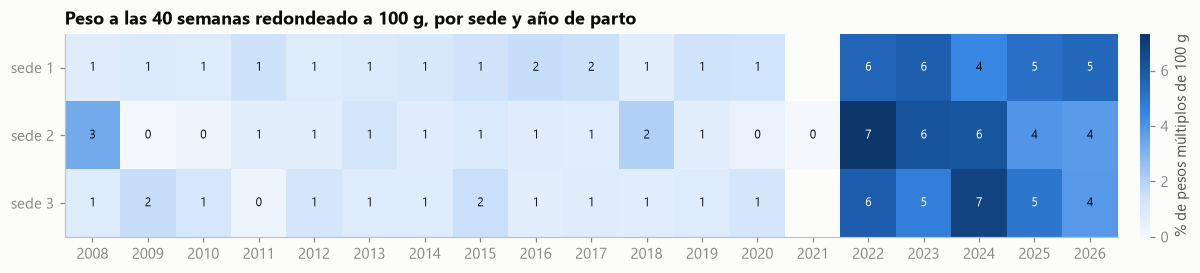

**Qué vemos.** La báscula tiene resolución de 1 g, pero casi todos los pesos terminan en 0, o sea que en la práctica se anotan de a 10 g. Lo más interesante es que los pesos redondeados a 100 g pasan de una mediana del **0,9%** antes de 2022 al **5,4%** después, en todas las sedes. Es otra huella del cambio de sistema o de proceso, y es justo el tipo de señal que debería vigilar la capa de sede.

In [18]:
heap = M.heaping_by(data.assign(anio=data.anio_parto), 'v218', ['iden_sede', 'anio'], min_n=100)
tabla_heap = heap.pivot(index='iden_sede', columns='anio', values='pct_multiplo_100q')
tabla_heap.index = [f'sede {int(i)}' for i in tabla_heap.index]
tabla_heap.columns = tabla_heap.columns.astype(int)
G.heatmap(tabla_heap, 'Peso a las 40 semanas redondeado a 100 g, por sede y año de parto', '% de pesos múltiplos de 100 g',
          fmt='{:.0f}', figsize=(13, 2.4))
plt.show()

antes_cambio = heap[heap.anio < anio_cambio].pct_multiplo_100q.median()
despues = heap[heap.anio >= anio_cambio].pct_multiplo_100q.median()
md(f'''**Qué vemos.** La báscula tiene resolución de 1 g, pero casi todos los pesos terminan en 0, o sea que en la práctica se anotan de a 10 g. Lo más interesante es que los pesos redondeados a 100 g pasan de una mediana del **{pct(antes_cambio)}** antes de {anio_cambio} al **{pct(despues)}** después, en todas las sedes. Es otra huella del cambio de sistema o de proceso, y es justo el tipo de señal que debería vigilar la capa de sede.''')

## 6. Capa de paciente: trayectorias

¿Podemos armar la trayectoria de cada niño y qué inconsistencias aparecen? En el adaptador declaramos tres **familias** de medidas repetidas (peso, talla y perímetro cefálico) en siete etapas, desde el nacimiento hasta los 12 meses de edad corregida. Cada etapa tiene su valor, su fecha y, cuando existe, la edad que se anotó en la visita.

Ojo con la edad. En el programa todo se maneja con **edad corregida**:

- Semanas de prematuridad = 40 − semanas de gestación al nacer
- Edad corregida = edad cronológica − semanas de prematuridad

Por eso la visita de 40 semanas es la edad corregida 0. En este notebook las visitas todavía se ubican con la edad cronológica y un margen de 120 días, que alcanza para cubrir a los más prematuros. El modelo sí va a usar la edad corregida (sección 10).

In [19]:
peso = M.long_family(data, spec.family('peso'), spec)
consistencia = M.age_consistency(peso)
display(consistencia)
md(f'''**Qué vemos.** La edad anotada en cada visita coincide con la edad que sale de restar la fecha de la visita y la fecha de parto (con 14 días de tolerancia) en más del **{pct(100 - consistencia.pct_discrepante.max())}** de los casos, en todas las etapas. **Esto es lo más importante para saber si el proyecto es viable:** aunque la base marque la mayoría de las mediciones como "sin ubicación temporal", con las fechas de las visitas sí podemos armar el eje temporal.''')

,n,mediana_diferencia,pct_discrepante
stage,,,
40 sem,14788,0,0
3 m EC,40264,0,"0,32"
6 m EC,33386,0,"0,30"
9 m EC,28580,0,"0,32"
12 m EC,25959,0,"0,32"


**Qué vemos.** La edad anotada en cada visita coincide con la edad que sale de restar la fecha de la visita y la fecha de parto (con 14 días de tolerancia) en más del **99,7%** de los casos, en todas las etapas. **Esto es lo más importante para saber si el proyecto es viable:** aunque la base marque la mayoría de las mediciones como "sin ubicación temporal", con las fechas de las visitas sí podemos armar el eje temporal.

In [20]:
resumen_tray = []
for fam in spec.families:
    largo = M.long_family(data, fam, spec)
    pares = M.trajectory_checks(largo, fam)
    consecutivas = [f'{a.key} -> {b.key}' for a, b in zip(fam.stages, fam.stages[1:])]
    r = M.summarize_trajectories(pares).reindex(consecutivas).assign(familia=fam.concept)
    resumen_tray.append(r)
resumen_tray = pd.concat(resumen_tray).reset_index().rename(columns={'index': 'transicion', 'transition': 'transicion'})
display(resumen_tray.set_index(['familia', 'transicion'])[['pares', 'mismo_dia', 'fechas_invertidas', 'disminuciones',
                                                          'velocidad_atipica', 'mediana_dias', 'mediana_cambio']])

pares  mismo_dia  fechas_invertidas  disminuciones  velocidad_atipica  mediana_dias  mediana_cambio
familia            transicion                                                                                                                    
peso               nacimiento -> entrada PMC  17355          0                  0              0                206            11              79
                   entrada PMC -> 40 sem      49058       3369                405              0                449            20             670
                   40 sem -> 3 m EC           35986         43                 61              0                299            93           2.690
                   3 m EC -> 6 m EC           33284         84                 73              0                434            92           1.330
                   6 m EC -> 9 m EC           27560        104                 60              0                346            91             900
                   9 m EC -> 12 m EC          24233         61                 53              0                328            92             720
talla              nacimiento -> entrada PMC  60735        124                332          20513               3782            12               0
                   entrada PMC -> 40 sem      48989       3369                406            303                967            20               3
                   40 sem -> 3 m EC           36076         43                 61             66                735            93           10,50
                   3 m EC -> 6 m EC           33406         84                 73            119                696            92               6
                   6 m EC -> 9 m EC           27574        104                 60            141                441            91            4,50
                   9 m EC -> 12 m EC          24214         61                 53            130                418            92            3,80
perimetro_cefalico nacimiento -> entrada PMC  54129        105                283           3261               3037            12               1
                   entrada PMC -> 40 sem      14758       2334                  0             47                264            16            1,70
                   40 sem -> 3 m EC           11002          0                  0             15                 50            93            5,40
                   3 m EC -> 6 m EC           33389         85                 72            165               1053            92            2,70
                   6 m EC -> 9 m EC           25775        104                 59            201                709            91            1,70
                   9 m EC -> 12 m EC          22561         60                 52            321                695            92            1,10

In [21]:
talla = resumen_tray[resumen_tray.familia == 'talla'].set_index('transicion')
baja_talla = talla.loc['nacimiento -> entrada PMC']
inv = resumen_tray[resumen_tray.familia == 'peso'].set_index('transicion').loc['entrada PMC -> 40 sem']
entrada_tarde = data.assign(ga=data.ga_semanas, tarde=(fechas['v195a'].date > fechas['v215'].date))
tarde_por_eg = entrada_tarde.dropna(subset=['ga']).groupby(pd.cut(entrada_tarde.ga, [0, 31, 34, 36, 45],
                labels=['<32', '32-34', '35-36', '37+']), observed=True).tarde.mean() * 100
display(tarde_por_eg.rename('% con entrada al PMC después de la visita de 40 semanas').to_frame())

md(f'''**Qué vemos**
- **La talla baja más de 1 cm entre el nacimiento y la entrada al programa en {fmt(baja_talla.disminuciones)} pacientes** ({pct(100 * baja_talla.disminuciones / baja_talla.pares, 0)} de los pares). Un niño no se encoge, así que lo más probable es que la talla al nacer se mida de otra forma o en otro lugar (en el hospital y no en el programa). Después de la entrada casi no hay disminuciones. Conclusión: no deberíamos usar la talla al nacer como punto de partida sin validarla antes.
- **En {fmt(inv.mismo_dia)} pacientes la entrada al programa y la visita de 40 semanas tienen la misma fecha**: probablemente se anotaron en la misma consulta. Entre dos etapas con la misma fecha no se puede calcular velocidad, así que el modelo debe tratarlas como una sola medición.
- Solo en **{fmt(inv.fechas_invertidas)} pacientes** la visita de 40 semanas queda antes de la entrada. Es menos del {pct(tarde_por_eg.max())} en cada grupo de edad gestacional, así que no se explica por la prematurez: son fechas mal anotadas o etapas mal asignadas, y van como alertas de la capa de medición.
- Las velocidades atípicas (a más de 4 desviaciones robustas en su transición) son pocas. Esas son las candidatas naturales para las alertas de la capa de paciente.''')

,% con entrada al PMC después de la visita de 40 semanas
ga,
<32,"0,57"
32-34,"0,49"
35-36,"0,77"
37+,"0,70"


**Qué vemos**
- **La talla baja más de 1 cm entre el nacimiento y la entrada al programa en 20.513 pacientes** (34% de los pares). Un niño no se encoge, así que lo más probable es que la talla al nacer se mida de otra forma o en otro lugar (en el hospital y no en el programa). Después de la entrada casi no hay disminuciones. Conclusión: no deberíamos usar la talla al nacer como punto de partida sin validarla antes.
- **En 3.369 pacientes la entrada al programa y la visita de 40 semanas tienen la misma fecha**: probablemente se anotaron en la misma consulta. Entre dos etapas con la misma fecha no se puede calcular velocidad, así que el modelo debe tratarlas como una sola medición.
- Solo en **405 pacientes** la visita de 40 semanas queda antes de la entrada. Es menos del 0,8% en cada grupo de edad gestacional, así que no se explica por la prematurez: son fechas mal anotadas o etapas mal asignadas, y van como alertas de la capa de medición.
- Las velocidades atípicas (a más de 4 desviaciones robustas en su transición) son pocas. Esas son las candidatas naturales para las alertas de la capa de paciente.

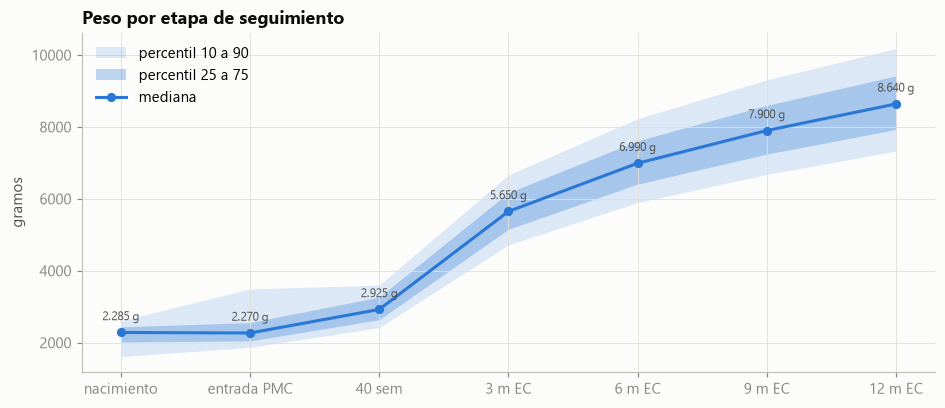

,valores a más de 3 DE de sus pares,%
stage,,
nacimiento,578,"3,33"
entrada PMC,1223,"1,98"
40 sem,468,"0,95"
3 m EC,582,"1,35"
6 m EC,353,"0,97"
9 m EC,313,"1,01"
12 m EC,356,"1,25"


La **comparación con pares** pone cada peso al lado del de niños parecidos: misma etapa, misma edad en la visita (por semana), misma edad gestacional y mismo sexo. Si en un grupo hay menos de 30 niños, se compara con un grupo más amplio. Así sacamos un "crecimiento esperado" sin depender de tablas externas, y la misma función sirve para cualquier variable continua. Los valores a más de 3 desviaciones de sus pares son las alertas candidatas de la capa de paciente.

In [22]:
peso['z'] = M.conditional_z(peso, ['age_bin', 'ga_semanas', 'sexo'], spec.min_cell)
orden = [s.key for s in spec.family('peso').stages]
cuantiles = peso.groupby('stage').value.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack().loc[orden]
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(orden))
ax.fill_between(x, cuantiles[0.1], cuantiles[0.9], color=G.SERIES[0], alpha=0.15, linewidth=0, label='percentil 10 a 90')
ax.fill_between(x, cuantiles[0.25], cuantiles[0.75], color=G.SERIES[0], alpha=0.30, linewidth=0, label='percentil 25 a 75')
ax.plot(x, cuantiles[0.5], color=G.SERIES[0], marker='o', markersize=5, label='mediana')
for i, v in enumerate(cuantiles[0.5]):
    ax.annotate(f'{fmt(v)} g', (i, v), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=8, color=G.INK_2)
ax.set_xticks(x, orden)
ax.set_title('Peso por etapa de seguimiento')
ax.set_ylabel('gramos')
ax.legend(loc='upper left')
plt.show()

alertas = peso.dropna(subset=['z']).assign(alerta=lambda d: d.z.abs() > 3).groupby('stage').alerta.agg(['sum', 'mean']).loc[orden]
alertas.columns = ['valores a más de 3 DE de sus pares', '%']
alertas['%'] *= 100
display(alertas)
md('''La **comparación con pares** pone cada peso al lado del de niños parecidos: misma etapa, misma edad en la visita (por semana), misma edad gestacional y mismo sexo. Si en un grupo hay menos de 30 niños, se compara con un grupo más amplio. Así sacamos un "crecimiento esperado" sin depender de tablas externas, y la misma función sirve para cualquier variable continua. Los valores a más de 3 desviaciones de sus pares son las alertas candidatas de la capa de paciente.''')

## 7. Capa de sede: ¿alguna mide distinto?

Aquí conviene separar dos cosas:

- **Nivel:** la sede es distinta a las demás todo el tiempo. Normalmente es por el tipo de pacientes o por el protocolo, no porque un instrumento esté dañado.
- **Cambio:** la sede se aparta de su propio pasado reciente a partir de cierta fecha. Así se vería una báscula que se descalibra o un cambio de procedimiento.

Que las sedes tengan niveles distintos es lo esperable: cada una está en un lugar distinto y sus pacientes viven situaciones sociales muy diferentes. Eso ya viene en los datos (las variables socioeconómicas), así que el modelo las usa como contexto y no juzga el nivel. Lo que vigila es el **cambio**: cada sede contra su propio pasado.

In [23]:
casuistica = data.assign(
    dias_a_entrada=(fechas['v195a'].date - parto).dt.days.where(lambda s: s.between(0, 400)),
    menor_32=data.ga_semanas < 32,
).groupby('iden_sede').agg(pacientes=('paciente_id', 'size'), eg_mediana=('ga_semanas', 'median'),
                           pct_menor_32_sem=('menor_32', 'mean'), peso_nacer_mediana=('ern_peso', 'median'),
                           dias_parto_a_entrada=('dias_a_entrada', 'median'), edad_visita_40s_dias=('v216', 'median'))
casuistica['pct_menor_32_sem'] *= 100
casuistica.index = [f'sede {int(i)}' for i in casuistica.index]
display(casuistica)
md('El peso al nacer de esta tabla sale solo de partos desde 2022, que es cuando se empezó a registrar (sección 3).')

,pacientes,eg_mediana,pct_menor_32_sem,peso_nacer_mediana,dias_parto_a_entrada,edad_visita_40s_dias
sede 1,29355,35,"13,37",2.260,11,27
sede 2,19234,36,"9,90","2.328,50",18,29
sede 3,13454,36,"7,43",2.280,9,26


El peso al nacer de esta tabla sale solo de partos desde 2022, que es cuando se empezó a registrar (sección 3).

,mediana (g) · sede 1,mediana (g) · sede 2,mediana (g) · sede 3,z ajustado por EG y sexo · sede 1,z ajustado por EG y sexo · sede 2,z ajustado por EG y sexo · sede 3,z ajustado además por edad en la visita · sede 1,z ajustado además por edad en la visita · sede 2,z ajustado además por edad en la visita · sede 3
stage,,,,,,,,,
nacimiento,2.260,"2.328,50",2.280,"-0,09","0,19","-0,08","-0,09","0,19","-0,08"
entrada PMC,2.200,2.540,2.200,"-0,17","0,78","-0,27","-0,09","0,33","-0,24"
40 sem,2.870,3.160,2.850,"-0,16","0,49","-0,14","-0,11","0,43","-0,21"
3 m EC,5.580,5.770,5.630,"-0,09","0,16","-0,03","-0,04","0,15","-0,08"
6 m EC,6.930,7.120,6.975,"-0,07","0,13","-0,02","-0,04","0,10","-0,05"
9 m EC,7.850,8.000,7.880,"-0,05","0,10","-0,01","-0,02","0,07","-0,03"
12 m EC,8.590,8.750,8.575,"-0,04","0,10","-0,04","-0,02","0,07","-0,05"


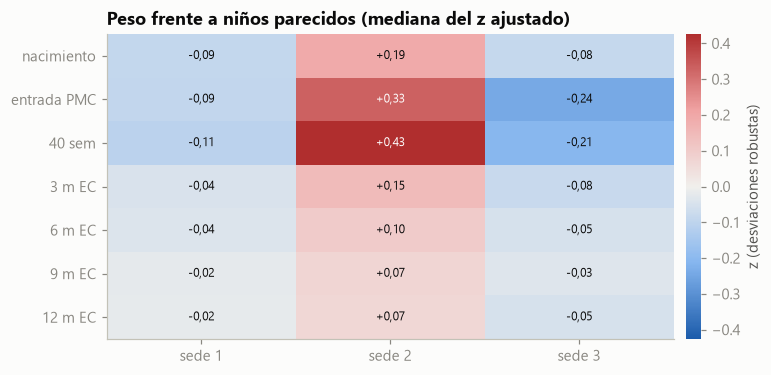

**Qué vemos**
- A las 40 semanas, la sede 2 pesa en la mediana **300 g más** que las otras dos. Ajustando por edad gestacional y sexo, la diferencia es de +0,49 DE. Si además ajustamos por la edad en la visita, baja a +0,43 DE: parte de la diferencia es porque la sede 2 recibe y controla a los niños más tarde (ver la tabla anterior).
- **La diferencia se achica desde los 3 meses**, cuando el momento de la visita depende menos de cada sede. Eso hace menos probable que sea la báscula, porque una báscula dañada movería el peso en todas las etapas.
- Este es justo el caso que anticipábamos en la propuesta: **sin ajuste, el observatorio culparía injustamente a la sede 2**. Toda comparación entre sedes tiene que ajustarse por tipo de pacientes y edad en la visita, y presentarse como hipótesis para que la revisen los expertos.

In [24]:
z_basico = M.conditional_z(peso, ['ga_semanas', 'sexo'], spec.min_cell)
comparacion = pd.concat({
    'mediana (g)': peso.groupby(['stage', 'group']).value.median().unstack(),
    'z ajustado por EG y sexo': peso.assign(z=z_basico).groupby(['stage', 'group']).z.median().unstack(),
    'z ajustado además por edad en la visita': peso.groupby(['stage', 'group']).z.median().unstack(),
}, axis=1).loc[orden]
comparacion.columns = [f'{a} · sede {int(b)}' for a, b in comparacion.columns]
display(comparacion)

tabla_z = peso.groupby(['stage', 'group']).z.median().unstack().loc[orden]
tabla_z.columns = [f'sede {int(c)}' for c in tabla_z.columns]
G.heatmap(tabla_z, 'Peso frente a niños parecidos (mediana del z ajustado)', 'z (desviaciones robustas)',
          fmt=sdec, cmap=G.DIVERGING, center=0, figsize=(7, 3.6))
plt.show()

d40 = comparacion.loc['40 sem']
md(f'''**Qué vemos**
- A las 40 semanas, la sede 2 pesa en la mediana **{fmt(d40["mediana (g) · sede 2"] - d40[["mediana (g) · sede 1", "mediana (g) · sede 3"]].mean())} g más** que las otras dos. Ajustando por edad gestacional y sexo, la diferencia es de {sdec(d40["z ajustado por EG y sexo · sede 2"])} DE. Si además ajustamos por la edad en la visita, baja a {sdec(d40["z ajustado además por edad en la visita · sede 2"])} DE: parte de la diferencia es porque la sede 2 recibe y controla a los niños más tarde (ver la tabla anterior).
- **La diferencia se achica desde los 3 meses**, cuando el momento de la visita depende menos de cada sede. Eso hace menos probable que sea la báscula, porque una báscula dañada movería el peso en todas las etapas.
- Este es justo el caso que anticipábamos en la propuesta: **sin ajuste, el observatorio culparía injustamente a la sede 2**. Toda comparación entre sedes tiene que ajustarse por tipo de pacientes y edad en la visita, y presentarse como hipótesis para que la revisen los expertos.''')

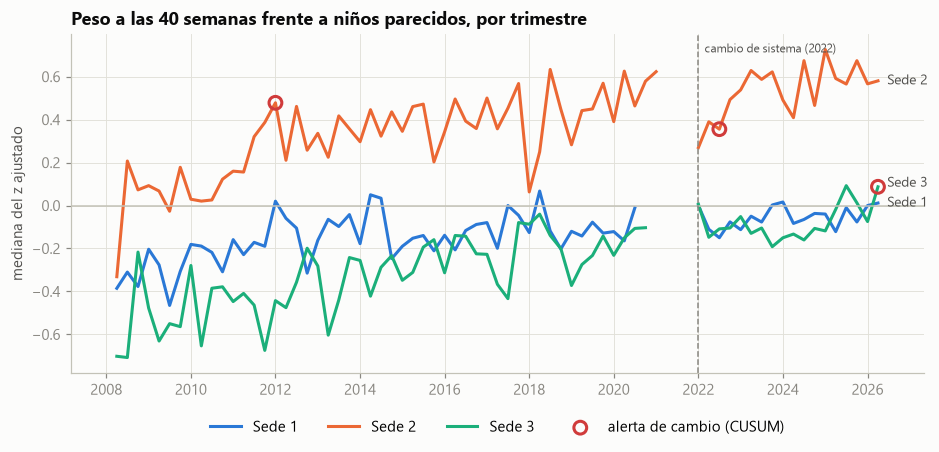

,etapa,sede,trimestre,n,mediana_z,nivel_propio,desvio_propio
0,40 sem,2,2012Q1,77,"0,48","0,14","0,34"
1,40 sem,2,2022Q3,282,"0,36","0,52","-0,16"
2,40 sem,3,2026Q2,208,"0,09","-0,09","0,18"
3,3 m EC,1,2013Q4,373,"0,13","-0,15","0,28"
4,3 m EC,1,2014Q2,324,"0,17","-0,07","0,24"
5,3 m EC,1,2016Q1,282,"-0,14","0,09","-0,23"
6,3 m EC,1,2016Q4,342,"-0,20","-0,04","-0,16"
7,3 m EC,2,2013Q2,188,"0,16","-0,03","0,19"
8,6 m EC,1,2014Q2,273,"0,06","-0,14","0,20"
9,6 m EC,1,2014Q4,244,"0,25","-0,08","0,32"


**Qué vemos.** El detector de cambios compara cada trimestre de una sede con la mediana de sus 8 trimestres anteriores y va acumulando las desviaciones que se sostienen (CUSUM). Con los datos reales salen **24 alertas** sobre 972 combinaciones de etapa, sede y trimestre. Esa tabla es justo lo que el observatorio le entregaría a los expertos: **casos para revisar, no conclusiones**. La línea punteada marca el cambio de sistema; cualquier alerta cerca de ella hay que mirarla con eso en mente. El trimestre que estaba en curso en la fecha de corte no se usa, porque está incompleto.

In [25]:
derivas = []
for etapa in ['40 sem', '3 m EC', '6 m EC', '9 m EC', '12 m EC']:
    m = peso.stage == etapa
    derivas.append(M.group_period_drift(peso[m], peso.z[m], cutoff=spec.cutoff).assign(etapa=etapa))
derivas = pd.concat(derivas, ignore_index=True)

serie = derivas[derivas.etapa == '40 sem']
ax = G.lines_by_group(serie, 'period', 'mediana_z', 'group', 'Peso a las 40 semanas frente a niños parecidos, por trimestre',
                      'mediana del z ajustado', baseline=0)
eventos = serie[serie.alarma_cusum]
ax.scatter(eventos.period, eventos.mediana_z, s=70, facecolors='none', edgecolors=G.CRITICAL, linewidths=2,
           label='alerta de cambio (CUSUM)', zorder=5)
ax.axvline(pd.Timestamp(f'{anio_cambio}-01-01'), color=G.MUTED, linestyle='--', linewidth=1)
ax.annotate(f'cambio de sistema ({anio_cambio})', (pd.Timestamp(f'{anio_cambio}-01-01'), ax.get_ylim()[1]),
            xytext=(4, -12), textcoords='offset points', fontsize=8, color=G.INK_2)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncols=4)
plt.show()

candidatos = derivas[derivas.alarma_cusum][['etapa', 'group', 'period', 'n', 'mediana_z', 'nivel_propio', 'desvio_propio']]
candidatos = candidatos.assign(sede=lambda d: d.group.astype(int), trimestre=lambda d: d.period.dt.to_period('Q').astype(str))
display(candidatos[['etapa', 'sede', 'trimestre', 'n', 'mediana_z', 'nivel_propio', 'desvio_propio']].reset_index(drop=True))
analizados = derivas.groupby(['etapa', 'group']).period.nunique().sum()
md(f'''**Qué vemos.** El detector de cambios compara cada trimestre de una sede con la mediana de sus 8 trimestres anteriores y va acumulando las desviaciones que se sostienen (CUSUM). Con los datos reales salen **{len(candidatos)} alertas** sobre {fmt(analizados)} combinaciones de etapa, sede y trimestre. Esa tabla es justo lo que el observatorio le entregaría a los expertos: **casos para revisar, no conclusiones**. La línea punteada marca el cambio de sistema; cualquier alerta cerca de ella hay que mirarla con eso en mente. El trimestre que estaba en curso en la fecha de corte no se usa, porque está incompleto.''')

## 8. Prueba: ¿el detector encuentra un error que metemos a propósito?

Como no tenemos casos etiquetados como anomalía, la propuesta plantea meter errores de tamaño conocido y ver si el detector los encuentra. Aquí simulamos una báscula de la sede 3 que, desde enero de 2024, suma entre 0 y 300 g a todos los pesos de los 3 meses, y medimos cuánto se demora en alertar. También pasamos a kilos el 0,5% de los pesos para ver si la capa de medición los encuentra.

In [26]:
inicio, sede, etapa = pd.Timestamp('2024-01-01'), 3.0, '3 m EC'
m = peso.stage == etapa
filas = []
for sesgo in [0, 50, 100, 150, 200, 300]:
    alterado = M.inject_shift(peso, sede, inicio, etapa, float(sesgo))
    z = M.conditional_z(alterado, ['age_bin', 'ga_semanas', 'sexo'], spec.min_cell)
    d = M.group_period_drift(alterado[m], z[m], cutoff=spec.cutoff)
    primera = M.first_alarm_after(d, sede, inicio, 'alarma_cusum')
    previas = d[(d.group == sede) & d.period.between(pd.Timestamp('2022-01-01'), inicio - pd.Timedelta(days=1))]
    filas.append(dict(sesgo_g=sesgo, valores_alterados=alterado.attrs['injected'],
                      primera_alerta=primera.to_period('Q').strftime('%Y-T%q') if primera is not None else 'no detectado',
                      trimestres_hasta_alerta=(primera.to_period('Q') - inicio.to_period('Q')).n + 1 if primera is not None else np.nan,
                      falsas_alertas_2022_2023=int(previas.alarma_cusum.sum())))
sintetico = pd.DataFrame(filas)
display(sintetico)

r = meta.set_index('variable').loc['v261']
errado, inyectados = M.inject_unit_errors(data.v261, 0.005, 1 / 1000)
marcados = M.flag_unit_errors(errado, r.range_min, r.range_max)
recall = marcados.loc[inyectados].mean() * 100
falsos = int(marcados.drop(inyectados).sum())

con_sesgo = sintetico[sintetico.sesgo_g > 0]
detectados = con_sesgo[con_sesgo.trimestres_hasta_alerta.notna()]
no_detectados = con_sesgo[con_sesgo.trimestres_hasta_alerta.isna()]
demoras = ', '.join(f'{r.sesgo_g} g en {r.trimestres_hasta_alerta:.0f} trimestre' + ('s' * (r.trimestres_hasta_alerta != 1))
                    for r in detectados.itertuples())
falsas_base = int(sintetico.loc[sintetico.sesgo_g == 0, 'falsas_alertas_2022_2023'].iloc[0])
md(f'''**Qué vemos**
- Sin sesgo, el detector da **{falsas_base} falsas alertas** en la sede 3 durante 2022 y 2023.
- El sesgo más pequeño que detecta es de **{detectados.sesgo_g.min()} g**, y entre más grande el sesgo, más rápido alerta: {demoras}.''' + (f''' Un sesgo de {", ".join(f"{s} g" for s in no_detectados.sesgo_g)} no se detecta.''' if len(no_detectados) else '') + f'''
- Estas son justo las métricas de "sesgo mínimo detectable" y "tiempo hasta detectar" que planteamos en la propuesta.
- Los pesos pasados a kilos se detectan en el **{pct(recall)}** de los casos, con **{falsos} falsos positivos** entre {fmt(data.v261.notna().sum())} valores.
- Ojo: esto muestra que el método funciona con estos datos, pero encontrar errores que metimos nosotros no prueba que encuentre bien las anomalías clínicas reales. Para eso necesitamos la revisión de los expertos.''')

,sesgo_g,valores_alterados,primera_alerta,trimestres_hasta_alerta,falsas_alertas_2022_2023
0,0,2037,no detectado,NaN,0
1,50,2037,no detectado,NaN,0
2,100,2037,2025-T4,8,0
3,150,2037,2024-T3,3,0
4,200,2037,2024-T2,2,0
5,300,2037,2024-T2,2,0


**Qué vemos**
- Sin sesgo, el detector da **0 falsas alertas** en la sede 3 durante 2022 y 2023.
- El sesgo más pequeño que detecta es de **100 g**, y entre más grande el sesgo, más rápido alerta: 100 g en 8 trimestres, 150 g en 3 trimestres, 200 g en 2 trimestres, 300 g en 2 trimestres. Un sesgo de 50 g no se detecta.
- Estas son justo las métricas de "sesgo mínimo detectable" y "tiempo hasta detectar" que planteamos en la propuesta.
- Los pesos pasados a kilos se detectan en el **100,0%** de los casos, con **0 falsos positivos** entre 43.236 valores.
- Ojo: esto muestra que el método funciona con estos datos, pero encontrar errores que metimos nosotros no prueba que encuentre bien las anomalías clínicas reales. Para eso necesitamos la revisión de los expertos.

## 9. Los retos que tenemos por delante

| # | Reto | Dónde lo vimos | Qué significa para el diseño |
|---|---|---|---|
| 1 | **El diccionario tiene los campos, pero con errores** | Secciones 2 y 4: rangos sacados de los datos, centinelas sin declarar, una unidad mal puesta, nombres repetidos y reglas de validación que fallan en casi todos los valores | Los rangos declarados no sirven para filtrar el entrenamiento. Combinamos las reglas del diccionario con estadística robusta y le reportamos los errores a la Fundación |
| 2 | **Las variables cambian con el tiempo** | Los expertos pueden agregar variables (sección 3: decenas ya empiezan a mitad de la historia); hay variables documentadas que no están en los datos y una columna categórica llena de texto libre (sección 4) | El modelo nunca nombra una variable: todo sale del esquema. Una variable nueva funciona desde su primer dato en la capa de valor |
| 3 | **El sistema de registro cambió en 2022 y hay un hueco en 2021** | Secciones 1 y 5: formato de fechas, más redondeo y caída del registro | Los quiebres conocidos entran al modelo como variables. Los detectores de cambio comparan con el pasado reciente y no con toda la historia |
| 4 | **Las sedes atienden poblaciones distintas** | Sección 7: la sede 2 recibe a los niños más tarde y pesa más en las primeras etapas | Es lo esperable por el contexto social de cada sede. Las variables socioeconómicas entran como contexto y cada sede se compara con su propio pasado. Ojo: esas variables también traen errores (ingresos imposibles) |
| 5 | **Solo hay 3 sedes** | Sección 7 | No podemos tratar las sedes como una población. La unidad de análisis es sede por periodo, y la señal fuerte es el cambio en el tiempo |
| 6 | **No hay etiquetas de anomalía** | Sección 8 | Validamos con errores sintéticos de tamaño conocido y con revisión de los expertos, incluidos casos que no alertaron. Como son temas clínicos, lo primero es que no se escapen errores |
| 7 | **Las trayectorias están incompletas** | Sección 3: la cobertura cae entre las 40 semanas y los 12 meses, y el peso al nacer solo existe desde 2022 | El modelo trabaja con lo que haya en cada etapa, sin exigir trayectorias completas ni imputar |
| 8 | **La talla al nacer no es comparable** | Sección 6: la talla baja entre el nacimiento y la entrada | Lo más probable es que se mida con otro instrumento. No la usamos como punto de partida de la trayectoria de talla |
| 9 | **Hay etapas con la misma fecha o en desorden** | Sección 6: muchas entradas al programa tienen la misma fecha que la visita de 40 semanas | Ordenar por fecha, juntar las mediciones del mismo día y marcar las invertidas como error |
| 10 | **Los datos de entrenamiento ya traen anomalías** | Secciones 2, 4 y 5: el -1 en la mayoría de los hematocritos, el redondeo a 100 g desde 2022 | Las raras no mueven la estadística robusta y la limpieza las saca. Las sistemáticas el modelo las aprende como normales, así que para esas usamos otras fuentes de verdad (sección 10) |
| 11 | **El seguimiento va por edad corregida** | Sección 6: aquí las visitas se ubican con edad cronológica y un margen | El modelo usa edad corregida, que depende de la edad gestacional al nacer: por indicación de la Fundación, `EG_Semanas` |
| 12 | **Gobierno de datos** | `iden_codigo` ("IdentificadorBebe") estaba expuesta en la capa de consumo, junto al identificador seudonimizado | No la usamos y le avisamos a la Fundación, que la restringió |

## 10. Cómo vamos a armar el modelo

Este es el diseño del modelo, armado con lo que vimos arriba. Está construido y validado con la base real en `modelo_anomalias.ipynb`, y se usa con `python -m anomalias`; aquí queda el porqué de cada decisión.

**La idea.** Una anomalía es un dato que está lejos de lo que esperamos para ese caso. Lo esperado lo aprende el modelo de los mismos datos, comparando cada dato con niños parecidos, en la misma etapa y con el mismo contexto.

**Qué recibe.** Los datos llegan desde la app en formato SEVARTI: seis tablas. El esquema de cada variable (tipo, unidad, rol, etapa, concepto y códigos especiales), las etapas con su ventana de edad, los sujetos (sede, fecha de nacimiento, edad gestacional), las mediciones en formato largo (una fila por dato, con fecha o edad), los episodios con inicio y fin (hospitalización, posición canguro) y los quiebres conocidos. El contexto socioeconómico entra como variables de rol "contexto". El modelo nunca nombra una variable, así que los expertos pueden agregar o quitar variables sin tocar código.

### Las capas

| Capa | Pregunta | Cómo | Dónde lo vimos aquí |
|---|---|---|---|
| **0. Contrato** | ¿El dato cumple el esquema? | Tipo, variable conocida y fecha posible. Si no cumple se rechaza: es un error de formato, no una anomalía | Sección 4 |
| **1. Valor** | ¿El valor tiene sentido por sí solo? | Mediana y MAD, códigos especiales y errores de unidad. Un código conocido cuenta como dato faltante, no como alerta | Sección 5 |
| **2. Contexto** | ¿Tiene sentido para este niño? | Un modelo por variable numérica (LightGBM por cuantiles) que da el rango esperado según etapa, edad corregida, covariables al nacer, contexto social, episodios activos y las demás variables de la etapa. Acepta huecos sin imputar | Sección 6, comparación con pares |
| **3. Trayectoria** | ¿Tiene sentido con su historia? | Las variables que miden lo mismo en distintas etapas se unen por su concepto: el cambio entre dos visitas frente al esperado para el tiempo que pasó, etapas en orden, fechas dentro de su ventana y reglas como "la talla no baja" | Sección 6 |
| **4. Grupo y tiempo** | ¿Una sede empezó a medir distinto? | Residuos de la capa 2, datos faltantes y redondeo por sede y trimestre, comparados con los últimos 8 trimestres de la misma sede | Secciones 7 y 8 |

Una variable nueva funciona desde su primer dato en la capa 1, y en la 3 si trae concepto. La capa 2 necesita su propio modelo; proponemos entrenarlo cuando la variable tenga unos 200 sujetos.

### Cómo entrenamos con datos sucios

Cada dato se decide por separado, según se use como objetivo o como entrada:

1. No imputamos ni corregimos valores.
2. Los rangos del diccionario no se usan como filtro, porque varios están mal (sección 2).
3. Para entrenar se excluye lo que la capa 1 reconoce como código especial o error de unidad, y lo que esté a más de 6 MAD. En inferencia la alerta salta a 3,5.
4. Limpieza en dos vueltas: se entrena, se saca el peor 1% de los residuos (solo si pasan de 3,5) y se vuelve a entrenar.
5. Los quiebres conocidos, como el de 2022, entran como variables.

Lo que se excluye queda en una máscara versionada. La base nunca se toca.

### ¿Y si los datos ya traen anomalías?

El modelo no supone que todos los datos son normales, sino que la mayoría lo es. Las anomalías raras (un 9999 suelto, un peso anotado en kilos) casi no mueven la mediana ni la pérdida por cuantiles, y la limpieza en dos vueltas las saca.

Las sistemáticas son otra cosa: si un error es común, el modelo lo aprende como normal. Para esas usamos otras fuentes de verdad:

| Qué usamos | Qué detecta | Ejemplo |
|---|---|---|
| Reglas del esquema | Lo imposible, aunque sea común | La talla no baja; el -1 del hematocrito es un código, no un valor |
| Revisión de patrones | Una forma rara de registrar | Demasiados pesos terminados en 00 |
| Capa 4 | Algo que empezó en algún momento | El cambio de 2022 |
| Expertos | Lo que siempre estuvo mal | La talla al nacer medida con otro instrumento |

Para el crecimiento hay un "normal" que no sale de nuestros datos: las curvas de la OMS, que usan las alertas clínicas (`alertas_clinicas.ipynb`).

### Cómo sabemos si funciona

- **Errores sintéticos:** se meten errores de tipo y tamaño conocidos en datos limpios de lo más reciente de cada régimen, sin niños repetidos entre entrenamiento y prueba. Es la prueba de la sección 8 extendida a todas las capas, y se compara con la regla que hay hoy (el rango del diccionario).
- **Expertos:** responden un archivo ciego con alertas de cada capa mezcladas con datos que no alertaron (`python -m retroalimentacion expertos`).
- **Métricas:** cuántos errores encuentra por tipo (lo primero, porque un error que se escapa es un problema clínico), falsas alertas por cada 1.000 datos y que agregar una variable no requiera cambiar código.

## 11. Qué sigue

**Para nosotros**

Lo primero ya está: los datos en SEVARTI, el banco de pruebas, las cinco capas y la herramienta de uso diario (`modelo_anomalias.ipynb` y `python -m anomalias`). Sigue:

1. Llevar a los expertos el archivo de `python -m retroalimentacion expertos` y medir con él qué tanto acierta cada capa.
2. Elegir `alpha` de la capa 2 con esa precisión.
3. Resolver las decisiones abiertas que tocan al modelo: las ventanas de cada visita y volver a usar la sede y la fecha de parto.

**Lo que ya respondió la Fundación:** la base se carga cada 6 meses; las estancias salen de sus duraciones (`hd_diasurn`, `hd_totaldiashospital`), sin restar fechas; para la edad corregida pidieron `EG_Semanas`; no hay un registro con fechas de los cambios de sistema, así que el de 2022 es el único declarado y la capa 4 vigila los demás. Los pesos extra con un campo de "días" que no es la edad se quedan, por ahora, en la fecha de su visita (también es una decisión abierta).

**Aviso resuelto:** la columna `iden_codigo` ("IdentificadorBebe") estaba disponible en la capa de consumo junto al identificador seudonimizado. Nunca la usamos, y la Fundación la retiró el 15 de octubre de 2026.

## Anexo A. Ficha de todas las variables

Una fila por variable del diccionario, con los chequeos que le tocan según su tipo. Esta tabla crece sola cuando se agregan variables.

In [29]:
ficha = perfil.join(meta.set_index('variable')[['source_type']]).reset_index()
columnas = ['variable', 'module', 'etiqueta', 'source_type', 'unidad', 'n', 'pct_cobertura', 'minimo', 'mediana', 'maximo',
            'n_fuera_rango', 'n_centinela', 'n_error_unidad', 'n_atipico_robusto', 'pct_terminal_0', 'n_categorias',
            'n_fecha_imposible', 'n_antes_de_anclaje', 'pct_hallazgos']
with pd.option_context('display.max_rows', 400):
    display(ficha[columnas].sort_values(['module', 'variable']).reset_index(drop=True))

,variable,module,etiqueta,source_type,unidad,n,pct_cobertura,minimo,mediana,maximo,n_fuera_rango,n_centinela,n_error_unidad,n_atipico_robusto,pct_terminal_0,n_categorias,n_fecha_imposible,n_antes_de_anclaje,pct_hallazgos
0,ac_adapseno,ac,Adaptacion al seno,CATEGORIC,NaN,34315,"55,31",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,NaN,0
1,ac_admgoteo,ac,Tecnica administracion por goteo,CATEGORIC,NaN,34304,"55,29",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN,0
2,ac_apoyolactancia,ac,Apoyo lactancia materna,BOOLEAN,NO/SI,34392,"55,43",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,0
3,ac_cansaninochupando,ac,El nino se cansa chupando,BOOLEAN,NO/SI,34325,"55,32",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,0
4,ac_cirujiaseno,ac,Madre tuvo cirugia de seno,BOOLEAN,NaN,34325,"55,32",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,0
5,ac_diasposcanguro,ac,Dias en posicion canguro EN HOSPITAL!! (HD),INTEGER,DIAS,32279,"52,03",0,4,88.888.888.888.888.896,1,0,0,2.022,"18,71",NaN,NaN,NaN,"0,00"
6,ac_enseposcangu,ac,Tuvo enseNanza sobre la PC,BOOLEAN,NO/SI,33664,"54,26",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,0
7,ac_entrenootrocuidador,ac,Otro cuidador se entrenO,BOOLEAN,NO/SI,34333,"55,34",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,0
8,ac_extraseno,ac,Tecnica extracciOn de leche a la salida,CATEGORIC,B/R/M,34314,"55,31",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,NaN,0
9,ac_lugarac,ac,Lugar de la adaptaciOn canguro,CATEGORIC,NaN,33992,"54,79",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN,NaN,0


## Anexo B. Cómo extenderlo

- **Una variable nueva en el diccionario:** no hay que hacer nada. Aparece sola en las secciones 2, 3 y 5 y en el anexo A.
- **Una variable que continúa una medida repetida** (por ejemplo, "peso a los 18 meses"): se agrega una etapa a la familia correspondiente en `sevarti/kmc.py`, con su variable de valor, de fecha y de edad.
- **Una covariable nueva para el crecimiento esperado:** se agrega a `covariates` en `build_spec`.
- **Una variable nueva en el modelo (sección 10):** funciona desde su primer dato en la capa 1, y en la 3 si trae concepto. La capa 2 la incorpora cuando tenga unos 200 sujetos.
- **Otra fuente de datos:** se escribe otro adaptador que entregue lo mismo (metadatos normalizados, tabla ancha y `DatasetSpec`). El motor y este notebook no cambian.

**Para correrlo:** instalar lo de `requirements.txt`, definir la variable de entorno `KMC_PW` con la clave de `kmc_estudiante` y ejecutar todas las celdas. Se demora unos dos minutos.